# **Genomic analysis of malaria vectors in The Gambia**

### **Discover genes under recent positive selection**


- In this notebook, we perform genome-wide selection scans using H12 for each of the chosen cohorts, and investigate any strong signals of selection.

In [ ]:
!pip install -q malariagen_data

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 36.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.1/216.1 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.7/71.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.9/775.9 kB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.3/211.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 M

In [ ]:
import malariagen_data
import plotly.express as px
import pandas as pd

In [ ]:
ag3 = malariagen_data.Ag3()
ag3

<MalariaGEN Ag3 API client>
Storage URL                           : gs://vo_agam_release_master_us_central1
Data releases available               : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14
Results cache                         : None
Cohorts analysis                      : 20250815
AIM analysis                          : 20220528
Site filters analysis                 : dt_20200416
Software version                      : malariagen_data 15.5.0
Client location                       : Iowa, United States (Google Cloud us-central1)
Data filtered to unrestricted use only: False
Data filtered to surveillance use only: False
Relevant data releases                : 3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 3.10, 3.11, 3.12, 3.13, 3.14
---
Please note that data are subject to terms of use,
for more information see https://www.malariagen.net/data
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v15.5.0/Ag3.html

In [ ]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'"

In [ ]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,VBS48172-6366STDY9854773,W2393,Kevin Opondo,"Gambia, The",Bullock,2019,9,13.181,-16.414,F,...,Brikama,GM-W,Foni Brefet,bissau,GM-W_biss_2019,GM-W_biss_2019_09,GM-W_biss_2019_Q3,GM-W_Foni-Brefet_biss_2019,GM-W_Foni-Brefet_biss_2019_09,GM-W_Foni-Brefet_biss_2019_Q3
378,VBS48173-6366STDY9854774,W0382,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
379,VBS48174-6366STDY9854775,W1168,Kevin Opondo,"Gambia, The",Tallinding,2019,9,13.437,-16.670,F,...,Kanifing,GM-W,Jeshwang,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Jeshwang_arab_2019,GM-W_Jeshwang_arab_2019_09,GM-W_Jeshwang_arab_2019_Q3
380,VBS48175-6366STDY9854776,W1807,Kevin Opondo,"Gambia, The",Brikama-A,2019,9,13.290,-16.657,F,...,Brikama,GM-W,Kombo Central,arabiensis,GM-W_arab_2019,GM-W_arab_2019_09,GM-W_arab_2019_Q3,GM-W_Kombo-Central_arab_2019,GM-W_Kombo-Central_arab_2019_09,GM-W_Kombo-Central_arab_2019_Q3


#### **Step 1: Choose cohorts**

In [ ]:
df_samples_gambia.groupby("cohort_admin2_year").size()

,0
cohort_admin2_year,
GM-L_Jarra-East_arab_2001,1
GM-L_Jarra-East_arab_2019,6
GM-L_Jarra-East_colu_2019,3
GM-M_Lower-Fuladu-West_arab_2019,51
GM-M_Lower-Fuladu-West_colu_2019,12
GM-M_Lower-Fuladu-West_gamb_2019,1
GM-M_Niamina-Dankunku_biss_2019,1
GM-M_Niamina-East_arab_2019,10
GM-M_Niamina-East_colu_2019,6


In [ ]:
groups = df_samples_gambia.groupby("cohort_admin2_year").size()

groups[groups > 10]

,0
cohort_admin2_year,
GM-M_Lower-Fuladu-West_arab_2019,51
GM-M_Lower-Fuladu-West_colu_2019,12
GM-M_Upper-Fuladu-West_arab_2019,12
GM-N_Lower-Niumi_arab_2019,13
GM-U_Basse_arab_2019,28
GM-U_Jimara_arab_2019,37
GM-U_Tumana_arab_2019,21
GM-W_Jeshwang_arab_2019,77
GM-W_Kombo-Central_arab_2019,28


- There are 43 cohorts (above), with 5 cohorts having more than 30 samples

    - arab cohorts

        - GM-M_Lower-Fuladu-West_arab_2019     -   **50**
        - GM-W_Jeshwang_arab_2019              -   **77**    (coast)
        - GM-U_Jimara_arab_2019                -   **37**
        
        - GM-U_Basse_arab_2019                 -   **28**
        - GM-W_Kombo-Central_arab_2019         -   **28**    (coast)
        - GM-U_Tumana_arab_2019                -   **21**
        - GM-M_Upper-Fuladu-West_arab_2019     -   **12**
        - GM-N_Lower-Niumi_arab_2019           -   **13**    (coast)
        
    - others
        - GM-L_Kiang-West_gcx2_2006            -   **19**
        - GM-M_Lower-Fuladu-West_gcx2_2012     -   **172**
        - GM-M_Lower-Fuladu-West_gcx2_2019     -   **12**
        - GM-N_Central-Badibu_gcx1_2011        -   **68**


- Chromosome arms: 2R, 2L, 3R, 3L, X

- Known insecticide resistance genes:

  - Cytochrome P450s - (Cyp6aa/p gene cluster)
  - Carboxylesterases (COEAE)
  - Glutathione S-Transferase (GSTs)

#### **Step 2: Calibrate window size**

&

#### **Step 3: Run GWSS with H12**

- **arab cohorts**

1st cohort - GM-M_Lower_Fuladu-West_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_arab_2019'",
)

Load haplotypes:   0%|          | 0/136 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
ag3.plot_h12_gwss?

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_arab_2019'",
    sample_sets="3.5",
    window_size=1000,
)

Load haplotypes:   0%|          | 0/199 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/154 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/181 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/136 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/46 [00:00<?, ?it/s]

2nd cohort - GM-W_Jeshwang_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    sample_query="cohort_admin2_year == 'GM-W_Jeshwang_arab_2019'",
)

Load haplotypes:   0%|          | 0/316 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-W_Jeshwang_arab_2019'",
    sample_sets="3.5",
    window_size=2000,
)

Load haplotypes:   0%|          | 0/463 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/358 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/421 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/316 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/106 [00:00<?, ?it/s]

3rd cohort - GM-U_Jimara_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    sample_query="cohort_admin2_year == 'GM-U_Jimara_arab_2019'",
)

Load haplotypes:   0%|          | 0/211 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-U_Jimara_arab_2019'",
    sample_sets="3.5",
    window_size=1000,
)

Load haplotypes:   0%|          | 0/309 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/239 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/281 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/211 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/71 [00:00<?, ?it/s]

4th cohort - GM-U_Basse_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-U_Basse_arab_2019'",
)

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-U_Basse_arab_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=1000,
)

Load haplotypes:   0%|          | 0/331 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/256 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/301 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/76 [00:00<?, ?it/s]

5th cohort - GM-W_Kombo-Central_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-W_Kombo-Central_arab_2019'",
)

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-W_Kombo-Central_arab_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=2000,
)

Load haplotypes:   0%|          | 0/331 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/256 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/301 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/76 [00:00<?, ?it/s]

In [ ]:
ag3.plot_h12_gwss?

6th cohort - GM-U_Tumana_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-U_Tumana_arab_2019'",
)

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
contig_colors=["#393b79", "#191919", "#191919", "#393b79", "#393b79"]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-U_Tumana_arab_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=1000,
    contig_colors=contig_colors,
)

Load haplotypes:   0%|          | 0/331 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/256 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/301 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/226 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/76 [00:00<?, ?it/s]

7th cohort - GM-M_Upper-Fuladu-West_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-M_Upper-Fuladu-West_arab_2019'",
)

Load haplotypes:   0%|          | 0/136 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-M_Upper-Fuladu-West_arab_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=1000,
)

Load haplotypes:   0%|          | 0/199 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/154 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/181 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/136 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/46 [00:00<?, ?it/s]

8th cohort - GM-N_Lower-Niumi_arab_2019

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="arab",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-N_Lower-Niumi_arab_2019'",
)

Load haplotypes:   0%|          | 0/181 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="arab",
    sample_query="cohort_admin2_year == 'GM-N_Lower-Niumi_arab_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=3000,
)

Load haplotypes:   0%|          | 0/265 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/205 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/241 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/181 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/61 [00:00<?, ?it/s]

- **coluzzii cohorts**

1st cohort - GM-M_Lower-Fuladu-West_colu_2012  -  172

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="gamb_colu",
    sample_sets="3.0",
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_colu_2012'",
)

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="gamb_colu",
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_colu_2012'",
    sample_sets="3.0",
    window_size=1000,
)

2nd cohort - GM-L_Kiang-West_colu_2006 - 19

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="gamb_colu",
    sample_sets="3.0",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-L_Kiang-West_colu_2006'",
)

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="gamb_colu",
    sample_query="cohort_admin2_year == 'GM-L_Kiang-West_colu_2006'",
    sample_sets="3.0",
    cohort_size=10,
    window_size=1000,
)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

3rd cohort - GM-M_Lower-Fuladu-West_colu_2019 - 12

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="gamb_colu",
    sample_sets="3.5",
    cohort_size=10,
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_colu_2019'",
)

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="gamb_colu",
    sample_query="cohort_admin2_year == 'GM-M_Lower-Fuladu-West_colu_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=1000,
)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

- **gcx1 cohorts**

GM-N_Central-Badibu_gcx1_2011 - 67

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="gamb_colu",
    sample_sets="3.0",
    sample_query="cohort_admin2_year == 'GM-N_Central-Badibu_gcx1_2011'",
)

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="gamb_colu",
    sample_query="cohort_admin2_year == 'GM-N_Central-Badibu_gcx1_2011'",
    sample_sets="3.0",
    window_size=2000,
)

In [ ]:
ag3.sample_sets(release=["3.0", "3.5"])

,sample_set,sample_count,study_id,study_url,terms_of_use_expiry_date,terms_of_use_url,release
0,AG1000G-AO,81,AG1000G-AO,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
1,AG1000G-BF-A,181,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
2,AG1000G-BF-B,102,AG1000G-BF-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
3,AG1000G-BF-C,13,AG1000G-BF-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
4,AG1000G-CD,76,AG1000G-CD,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
5,AG1000G-CF,73,AG1000G-CF,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
6,AG1000G-CI,80,AG1000G-CI,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
7,AG1000G-CM-A,303,AG1000G-CM-1,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
8,AG1000G-CM-B,97,AG1000G-CM-2,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0
9,AG1000G-CM-C,44,AG1000G-CM-3,https://www.malariagen.net/partner_study/AG100...,2025-01-01,https://www.malariagen.net/data/our-approach-s...,3.0


In [ ]:
ag3.sample_metadata(sample_sets="1272-VO-GM-OPONDO-VMF00160", sample_query="cohort_admin2_year == 'GM-U_Jimara_gamb_2019'")

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47801-6366STDY9854406,E0462,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_10,GM-U_gamb_2019_Q4,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_10,GM-U_Jimara_gamb_2019_Q4
1,VBS47811-6366STDY9854415,E0523,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_10,GM-U_gamb_2019_Q4,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_10,GM-U_Jimara_gamb_2019_Q4
2,VBS47816-6366STDY9854420,E0481,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_10,GM-U_gamb_2019_Q4,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_10,GM-U_Jimara_gamb_2019_Q4
3,VBS47818-6366STDY9854422,E2933,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3
4,VBS47822-6366STDY9854428,E1720,Kevin Opondo,"Gambia, The",Damba kunda Kuta,2019,10,13.260,-14.268,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_10,GM-U_gamb_2019_Q4,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_10,GM-U_Jimara_gamb_2019_Q4
5,VBS47839-6366STDY9854444,E2934,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3
6,VBS47843-6366STDY9854448,E0992,Kevin Opondo,"Gambia, The",Kossemar,2019,9,13.331,-14.376,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3
7,VBS47867-6366STDY9854470,E2901,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3
8,VBS48084-6366STDY9854684,E2957,Kevin Opondo,"Gambia, The",Gambisara,2019,9,13.236,-14.310,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3
9,VBS48109-6366STDY9854709,E1914,Kevin Opondo,"Gambia, The",Kossemar,2019,9,13.331,-14.376,F,...,Basse,GM-U,Jimara,gambiae,GM-U_gamb_2019,GM-U_gamb_2019_09,GM-U_gamb_2019_Q3,GM-U_Jimara_gamb_2019,GM-U_Jimara_gamb_2019_09,GM-U_Jimara_gamb_2019_Q3


**GM-U_Jimara_gamb_2019 - 10**

In [ ]:
ag3.plot_h12_calibration(
    contig="3L",
    analysis="gamb_colu",
    sample_sets="3.5",
    sample_query="cohort_admin2_year == 'GM-U_Jimara_gamb_2019'",
    cohort_size=10
)

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
for contig in ag3.contigs:
  ag3.plot_h12_gwss(
    contig=contig,
    analysis="gamb_colu",
    sample_query="cohort_admin2_year == 'GM-U_Jimara_gamb_2019'",
    sample_sets="3.5",
    cohort_size=10,
    window_size=1000,
)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h12.py:462: UserWarning: found multiple competing values 

### **Adaptive introgression between An gambiae and An arabiensis**

GM-W_Jeshwang_arab_2019 - 77

GM-U_Jimara_arab_2019 - 37

GM-U_Jimara_gamb_2019 - 10

In [ ]:
ag3.plot_h1x_gwss(
    contig="2R",
    analysis="gamb_colu_arab",
    sample_sets="3.5",
    cohort1_query="cohort_admin2_year == 'GM-U_Jimara_arab_2019'",
    cohort2_query="cohort_admin2_year == 'GM-U_Jimara_gamb_2019'",
    cohort_size=10,
    window_size=1000,
)

/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/genome_features.py:365: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data.fillna("", inplace=True)
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h1x.py:309: UserWarning: found multiple competing values for 'toolbar.active_drag' property; using the latest value
  fig = bokeh.layouts.gridplot(
/home/conda/global/88791d444fdbce46806165cd4d538245572746a5af1d9cd18e089e6c30a3c9c8-20240621-102357-200529-70-mgenv-5.1.0/lib/python3.10/site-packages/malariagen_data/anoph/h1x.py:309: UserWarning: found multiple competing values 

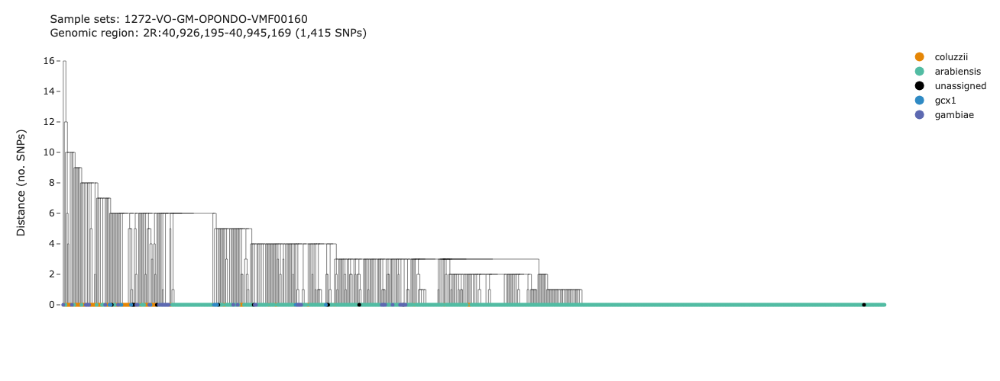

In [ ]:
# haplotype clustering

ag3.plot_haplotype_clustering(
    region='2R:40,926,195-40,945,169',
    analysis='gamb_colu_arab',
    sample_sets='1272-VO-GM-OPONDO-VMF00160',
    #sample_query= "country == 'Gambia, The' and contributor not in ['Alfred Amambua-Ngwa']",
    color='taxon',
    #symbol='admin1_name'
)

Load haplotypes:   0%|          | 0/170 [00:00<?, ?it/s]

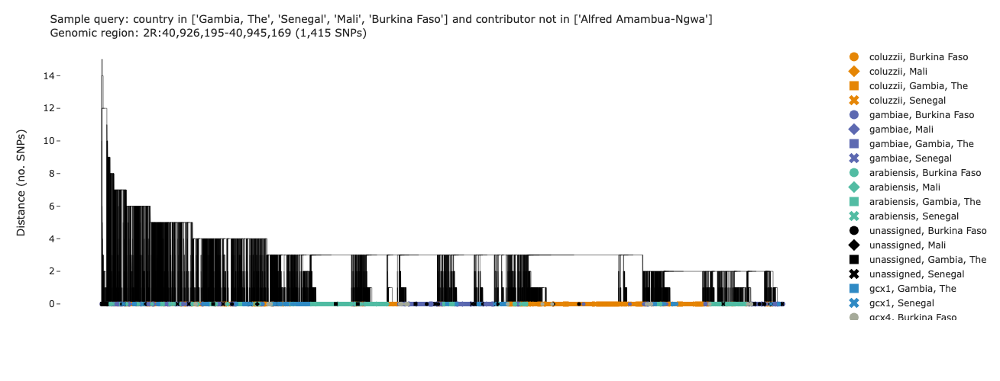

In [ ]:
# haplotype clustering arabiensis west african countries - to check if it's an arabiensis sweep for the KEAP1 gene

ag3.plot_haplotype_clustering(
    region='2R:40,926,195-40,945,169',
    analysis='gamb_colu_arab',
    #sample_sets='1272-VO-GM-OPONDO-VMF00160',
    sample_query= "country in ['Gambia, The', 'Senegal', 'Mali', 'Burkina Faso'] and contributor not in ['Alfred Amambua-Ngwa']",
    color='taxon',
    symbol='country'
)

**KEAP1 Sweep - Could be an arabiensis problem, with potential spatial gene flow between Mali, Senegal and The Gambia**

In [ ]:
cypo_keap1_peak_genes_df = (
    ag3.genome_features(region="2R:40,926,195-40,945,169")
    .query('type == "gene"')
    [["contig", "start", "end", "ID", "Name", "description"]]
    .set_index("ID")
)
peak_genes_df

#### **CNV Frequencies for the observed genes**

Cytochrome P450s - (Cyp6aa/p gene cluster)

Carboxylesterases (COE)

Glutathione S-Transferase (GSTs)

In [ ]:
cyp6aap_region = "2R:28,480,000-28,510,000"
cyp9k1_region = "X:15,240,000-15,250,000"
coeae_region = "2L:37,233,000-37,330,000"
gst_region = "3R:28,400,000-28,605,000"
cohorts = "admin2_year"
sample_sets = ["3.0", "3.5"]

In [ ]:
cnv_freqs_df_gambia = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=[cyp6aap_region,cyp9k1_region,coeae_region,gst_region],
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
cnv_freqs_df_gambia

Load CNV HMM data:   0%|          | 0/58 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/11 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/58 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/1 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/58 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/12 [00:00<?, ?it/s]

Load CNV HMM data:   0%|          | 0/58 [00:00<?, ?it/s]

Compute modal gene copy number:   0%|          | 0/13 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP002859 NaN       amp                +   
                     del                +   
AGAP002862 CYP6AA1   amp                -   
                     del                -   
AGAP013128 CYP6AA2   amp                -   
...                                   ...   
AGAP009195 GSTE1     del                -   
AGAP009196 GSTE7     amp                +   
                     del                +   
AGAP009197 GSTE3     amp                -   
                     del                -   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP002859 NaN       amp       solute carrier family 8 (sodium/calcium exchan...   
                     del       solute carrier family 8 (sodium/calcium exchan...   
AGAP002862 CYP6AA1   amp        cytochrome P450 [Source:VB Community Annotation]   
                     del        cytochrome P450 [Source:VB Community Annotation]   
AGAP013128 CYP6AA2   amp        cytochrome P450 [Source:VB Community Annotation]   
...                                                                          ...   
AGAP009195 GSTE1     del       glutathione S-transferase epsilon class 1 [Sou...   
AGAP009196 GSTE7     amp       glutathione S-transferase epsilon class 7 [Sou...   
                     del       glutathione S-transferase epsilon class 7 [Sou...   
AGAP009197 GSTE3     amp       glutathione S-transferase epsilon class 3 [Sou...   
                     del       glutathione S-transferase epsilon class 3 [Sou...   

                              contig     start       end  \
gene_id    gene_name cnv_type                              
AGAP002859 NaN       amp          2R  28397312  28516028   
                     del          2R  28397312  28516028   
AGAP002862 CYP6AA1   amp          2R  28480576  28482637   
                     del          2R  28480576  28482637   
AGAP013128 CYP6AA2   amp          2R  28483301  28484921   
...                              ...       ...       ...   
AGAP009195 GSTE1     del          3R  28598871  28599816   
AGAP009196 GSTE7     amp          3R  28600347  28601354   
                     del          3R  28600347  28601354   
AGAP009197 GSTE3     amp          3R  28601368  28602280   
                     del          3R  28601368  28602280   

                               frq_GM-M_Lower-Fuladu-West_arab_2019  \
gene_id    gene_name cnv_type                                         
AGAP002859 NaN       amp                                   0.000000   
                     del                                   0.000000   
AGAP002862 CYP6AA1   amp                                   0.210526   
                     del                                   0.000000   
AGAP013128 CYP6AA2   amp                                   0.210526   
...                                                             ...   
AGAP009195 GSTE1     del                                   0.000000   
AGAP009196 GSTE7     amp                                   0.000000   
                     del                                   0.000000   
AGAP009197 GSTE3     amp                                   0.000000   
                     del                                   0.000000   

                               frq_GM-U_Basse_arab_2019  \
gene_id    gene_name cnv_type                             
AGAP002859 NaN       amp                       0.000000   
                     del                       0.000000   
AGAP002862 CYP6AA1   amp                       0.200000   
                     del                       0.000000   
AGAP013128 CYP6AA2   amp                       0.066667   
...                                                 ...   
AGAP009195 GSTE1     del                       0.000000   
AGAP009196 GSTE7     amp                       0.066667   
                     del                       0.000000 

In [ ]:
df_cnv_gambia_cohorts = (
    df_samples_gambia
    .groupby("cohort_admin2_year")
    .aggregate({
        "latitude":"mean",
        "longitude":"mean",
        "sample_id":"count",
        "taxon":"first"
    })
    .query("sample_id>=10")
    .sort_values("longitude")
)
df_cnv_gambia_cohorts

,latitude,longitude,sample_id,taxon
cohort_admin2_year,,,,
GM-W_Jeshwang_arab_2019,13.437247,-16.670987,77,arabiensis
GM-W_Kombo-Central_arab_2019,13.290000,-16.657000,28,arabiensis
GM-N_Lower-Niumi_arab_2019,13.481000,-16.515000,13,arabiensis
GM-L_Kiang-West_colu_2006,13.417000,-16.033000,19,coluzzii
GM-N_Central-Badibu_gcx1_2011,13.550000,-15.900000,67,gcx1
GM-M_Niamina-East_arab_2019,13.619500,-15.157000,10,arabiensis
GM-M_Lower-Fuladu-West_colu_2012,13.567000,-14.917000,172,coluzzii
GM-M_Lower-Fuladu-West_colu_2019,13.542333,-14.910500,12,coluzzii
GM-M_Lower-Fuladu-West_arab_2019,13.530320,-14.901180,50,arabiensis


In [ ]:
df_cnv_gm_cohorts = df_cnv_gambia_cohorts.index.tolist()
df_cnv_gm_cohorts

['GM-W_Jeshwang_arab_2019',
 'GM-W_Kombo-Central_arab_2019',
 'GM-N_Lower-Niumi_arab_2019',
 'GM-L_Kiang-West_colu_2006',
 'GM-N_Central-Badibu_gcx1_2011',
 'GM-M_Niamina-East_arab_2019',
 'GM-M_Lower-Fuladu-West_colu_2012',
 'GM-M_Lower-Fuladu-West_colu_2019',
 'GM-M_Lower-Fuladu-West_arab_2019',
 'GM-M_Upper-Fuladu-West_arab_2019',
 'GM-U_Jimara_arab_2019',
 'GM-U_Jimara_gamb_2019',
 'GM-U_Basse_arab_2019',
 'GM-U_Tumana_arab_2019']

In [ ]:
all_cohorts_admin2_year = [
    'GM-W_Jeshwang_arab_2019',
    'GM-W_Kombo-Central_arab_2019',
    'GM-N_Central-Badibu_gcx1_2011',
    'GM-M_Lower-Fuladu-West_gcx2_2012',
    'GM-M_Lower-Fuladu-West_arab_2019',
    'GM-U_Jimara_arab_2019',
    'GM-U_Basse_arab_2019',
]

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in all_cohorts_admin2_year]],
                             title="Gene CNV frequencies, Cyp6aa/p locus + Cyp9k1 + Coeae + Gst")

In [ ]:
cnv_freqs_df_gambia.columns

Index(['gene_strand', 'gene_description', 'contig', 'start', 'end',
       'frq_GM-M_Lower-Fuladu-West_arab_2019',
       'frq_GM-M_Lower-Fuladu-West_colu_2012',
       'frq_GM-N_Central-Badibu_gcx1_2011', 'frq_GM-U_Basse_arab_2019',
       'frq_GM-U_Jimara_arab_2019', 'frq_GM-W_Jeshwang_arab_2019',
       'frq_GM-W_Kombo-Central_arab_2019', 'max_af', 'windows', 'label'],
      dtype='object')

In [ ]:
arab_cohorts_cnv_admin2_year = [
    'GM-W_Jeshwang_arab_2019',
    'GM-W_Kombo-Central_arab_2019',
    'GM-M_Lower-Fuladu-West_arab_2019',
    'GM-U_Jimara_arab_2019',
    'GM-U_Basse_arab_2019',
]

In [ ]:
gambcolu_cohorts_cnv_admin2_year = [
    'GM-N_Central-Badibu_gcx1_2011',
    'GM-M_Lower-Fuladu-West_colu_2012',
]

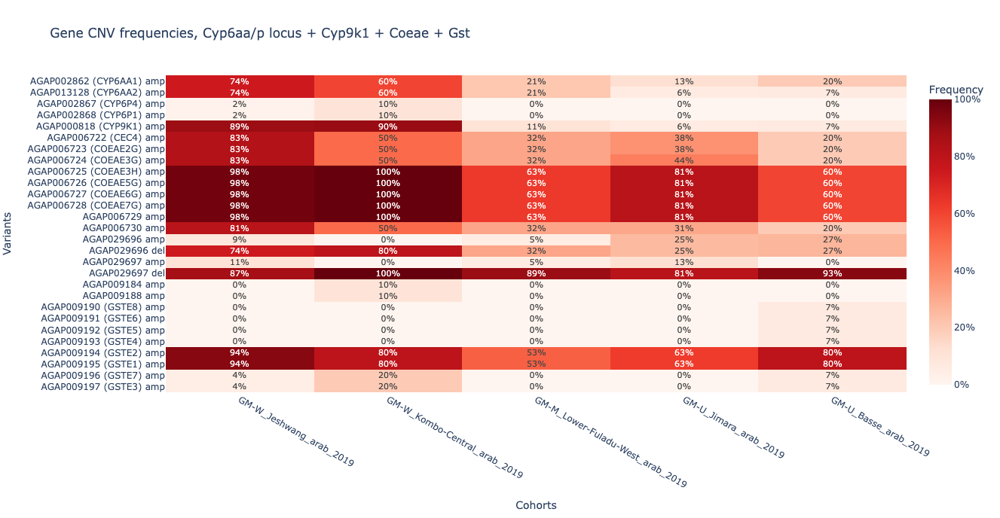

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab_cohorts_cnv_admin2_year]],
    title="Gene CNV frequencies, Cyp6aa/p locus + Cyp9k1 + Coeae + Gst",
    row_height=16,
)

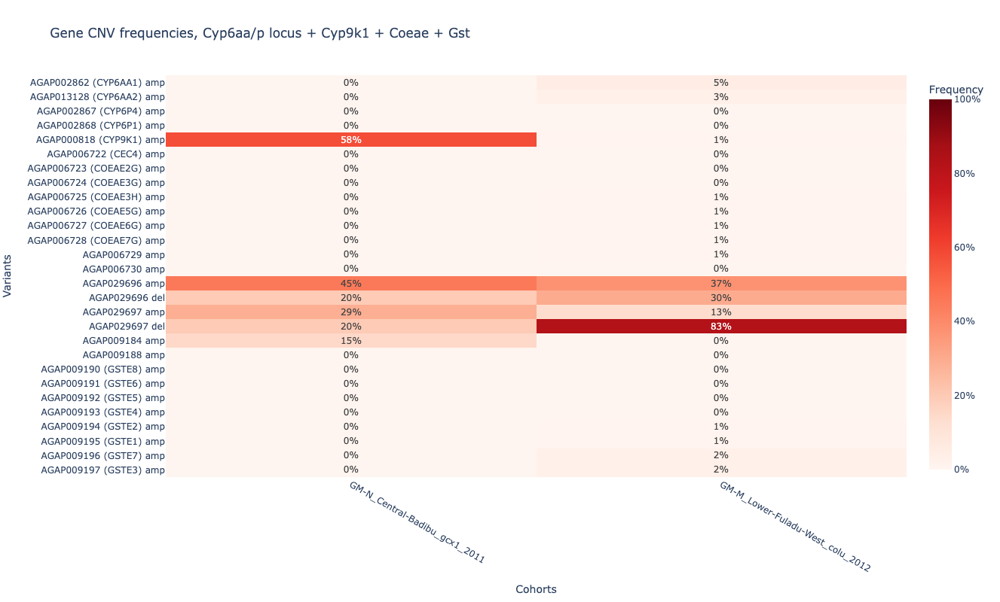

In [ ]:
ag3.plot_frequencies_heatmap(
    cnv_freqs_df_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in gambcolu_cohorts_cnv_admin2_year]],
                             title="Gene CNV frequencies, Cyp6aa/p locus + Cyp9k1 + Coeae + Gst"
)

In [ ]:
coe_cnv_freqs_df_gambia = ag3.gene_cnv_frequencies(
    sample_query=gambia_sample_query,
    region=coeae_region,
    cohorts=cohorts,
    sample_sets=sample_sets,
    drop_invariant=False,
    )
coe_cnv_freqs_df_gambia

Compute modal gene copy number:   0%|          | 0/12 [00:00<?, ?it/s]

gene_strand  \
gene_id    gene_name cnv_type               
AGAP006721 NaN       amp                -   
                     del                -   
AGAP006722 CEC4      amp                +   
                     del                +   
AGAP006723 COEAE2G   amp                -   
                     del                -   
AGAP006724 COEAE3G   amp                -   
                     del                -   
AGAP006725 COEAE3H   amp                -   
                     del                -   
AGAP006726 COEAE5G   amp                +   
                     del                +   
AGAP006727 COEAE6G   amp                -   
                     del                -   
AGAP006728 COEAE7G   amp                +   
                     del                +   
AGAP006729 NaN       amp                -   
                     del                -   
AGAP006730 NaN       amp                -   
                     del                -   
AGAP029696 NaN       amp                -   
                     del                -   
AGAP029697 NaN       amp                +   
                     del                +   

                                                                gene_description  \
gene_id    gene_name cnv_type                                                      
AGAP006721 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP006722 CEC4      amp       cecropin anti-microbial peptide [Source:VB Com...   
                     del       cecropin anti-microbial peptide [Source:VB Com...   
AGAP006723 COEAE2G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006724 COEAE3G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006725 COEAE3H   amp       carboxylesterase alpha esterase [Source:VB Com...   
                     del       carboxylesterase alpha esterase [Source:VB Com...   
AGAP006726 COEAE5G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006727 COEAE6G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006728 COEAE7G   amp       carboxylesterase [Source:VB Community Annotation]   
                     del       carboxylesterase [Source:VB Community Annotation]   
AGAP006729 NaN       amp       Ester hydrolase C11orf54 [Source:VB Community ...   
                     del       Ester hydrolase C11orf54 [Source:VB Community ...   
AGAP006730 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP029696 NaN       amp                                                     NaN   
                     del                                                     NaN   
AGAP029697 NaN       amp                                                     NaN   
                     del                                                     NaN   

                              contig     start       end  \
gene_id    gene_name cnv_type                              
AGAP006721 NaN       amp          2L  37184049  37235094   
                     del          2L  37184049  37235094   
AGAP006722 CEC4      amp          2L  37233354  37233690   
                     del          2L  37233354  37233690   
AGAP006723 COEAE2G   amp          2L  37282152  37285191   
                     del          2L  37282152  37285191   
AGAP006724 COEAE3G   amp          2L  37285915  37288160   
                     del          2L  37285915  37288160   
AGAP006725 COEAE3H   amp          2L  37288762  37290797   
              

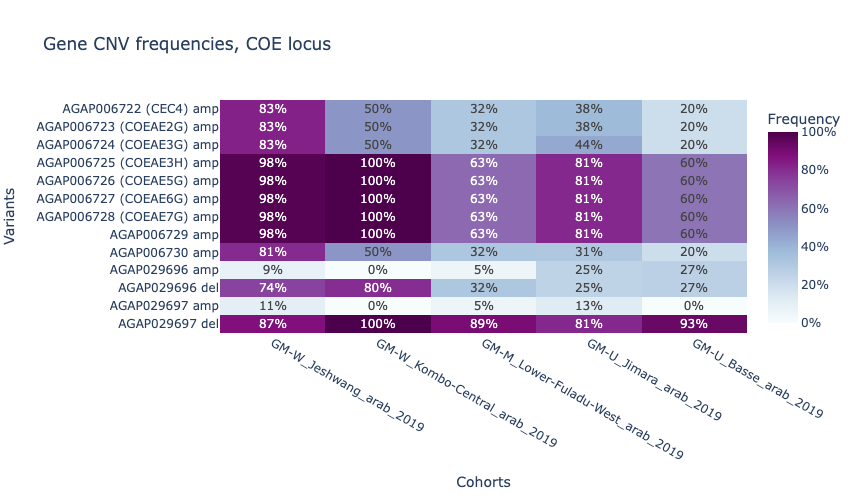

In [ ]:
ag3.plot_frequencies_heatmap(
    coe_cnv_freqs_df_gambia.query("max_af > 0.05")[["label"] + [f"frq_{c}" for c in arab_cohorts_cnv_admin2_year]],
    title="Gene CNV frequencies, COE locus",
    color_continuous_scale="BuPu"
)